# RainCast: Rain Prediction with ML, Data Science, IoT and Soft Computing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OMDATTA/rain-prediction/blob/main/notebooks/Rain_Prediction.ipynb)

This notebook trains the models behind the RainCast web app. It predicts **whether it will rain tomorrow, how likely it is, and what type of rain to expect**, using:

| Area | What is used |
|---|---|
| **Historical data** | Kaggle *Rain in Australia* (weatherAUS): about 145k daily observations from 49 stations, 2007–2017 |
| **Current data** | Open-Meteo live conditions, the past 7 days, and 10-year climatology for any city |
| **Data science** | EDA, missing-value analysis, feature engineering, chronological train/val/test split |
| **Machine learning** | Logistic Regression, Random Forest, Gradient Boosting, MLP neural network, plus a rainfall-amount regressor |
| **Soft computing** | Mamdani fuzzy inference (18 rules), a fuzzy rain-type classifier (IMD categories), and a genetic algorithm that optimises the ensemble |
| **IoT** | Simulated ESP32 sensor stream (BME280 + FC-37 rain plate) sent through the same engine |

The trained models are exported to `rainlib/model.json`, which the Vercel serverless API loads with **pure Python**, so no scikit-learn is needed in production.

## 1. Setup

In [1]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB and not os.path.exists('rain-prediction'):
    !git clone https://github.com/OMDATTA/rain-prediction.git
if IN_COLAB:
    %cd rain-prediction
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())
!pip -q install kagglehub scikit-learn pandas matplotlib seaborn

In [2]:
import json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='Blues_d')
plt.rcParams['figure.dpi'] = 110
from rainlib.features import FEATURES, COMPASS
from rainlib import fuzzy
from src.train import load_dataset, split_by_time, impute, fuzzy_scores, metrics, export_trees, gbm_init_raw
from src.genetic import optimise

## 2. Historical data from Kaggle
`kagglehub` downloads the public dataset (in Colab, sign in to Kaggle if prompted). As an alternative, upload `kaggle.json` and use the Kaggle CLI.

In [3]:
DATA = 'data/weatherAUS.csv'
if not os.path.exists(DATA):
    import kagglehub, shutil, glob
    path = kagglehub.dataset_download('jsphyg/weather-dataset-rattle-package')
    os.makedirs('data', exist_ok=True)
    shutil.copy(glob.glob(os.path.join(path, '*.csv'))[0], DATA)
raw = pd.read_csv(DATA, parse_dates=['Date'])
print(raw.shape)
raw.head()

(142193, 24)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,1.0,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0.2,No


## 3. Exploratory data analysis

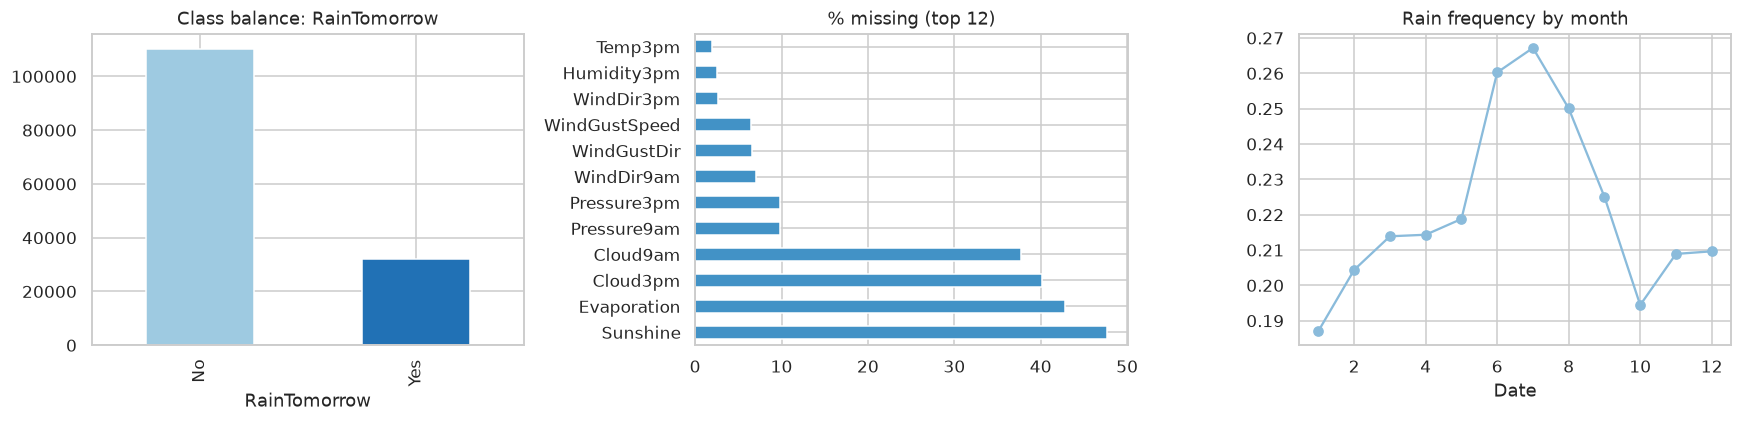

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
raw['RainTomorrow'].value_counts().plot.bar(ax=ax[0], color=['#9ecae1', '#2171b5']); ax[0].set_title('Class balance: RainTomorrow')
(raw.isna().mean().sort_values(ascending=False)[:12] * 100).plot.barh(ax=ax[1], color='#4292c6'); ax[1].set_title('% missing (top 12)')
raw.groupby(raw.Date.dt.month)['RainToday'].apply(lambda s: (s == 'Yes').mean()).plot(ax=ax[2], marker='o'); ax[2].set_title('Rain frequency by month')
plt.tight_layout(); plt.show()

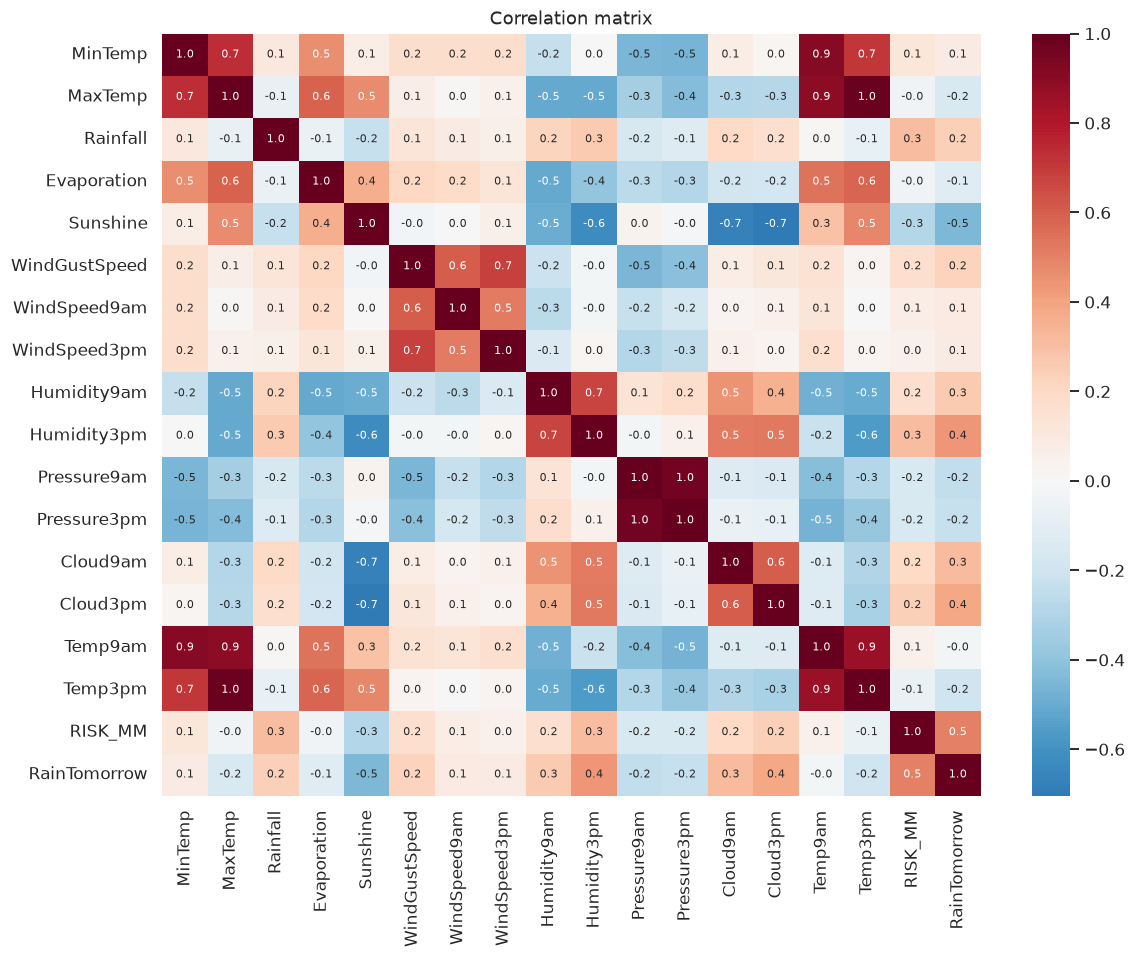

In [5]:
num = raw.select_dtypes('number').columns
plt.figure(figsize=(12, 9))
corr = raw.assign(RainTomorrow=(raw.RainTomorrow == 'Yes').astype(float))[list(num) + ['RainTomorrow']].corr()
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Correlation matrix'); plt.show()

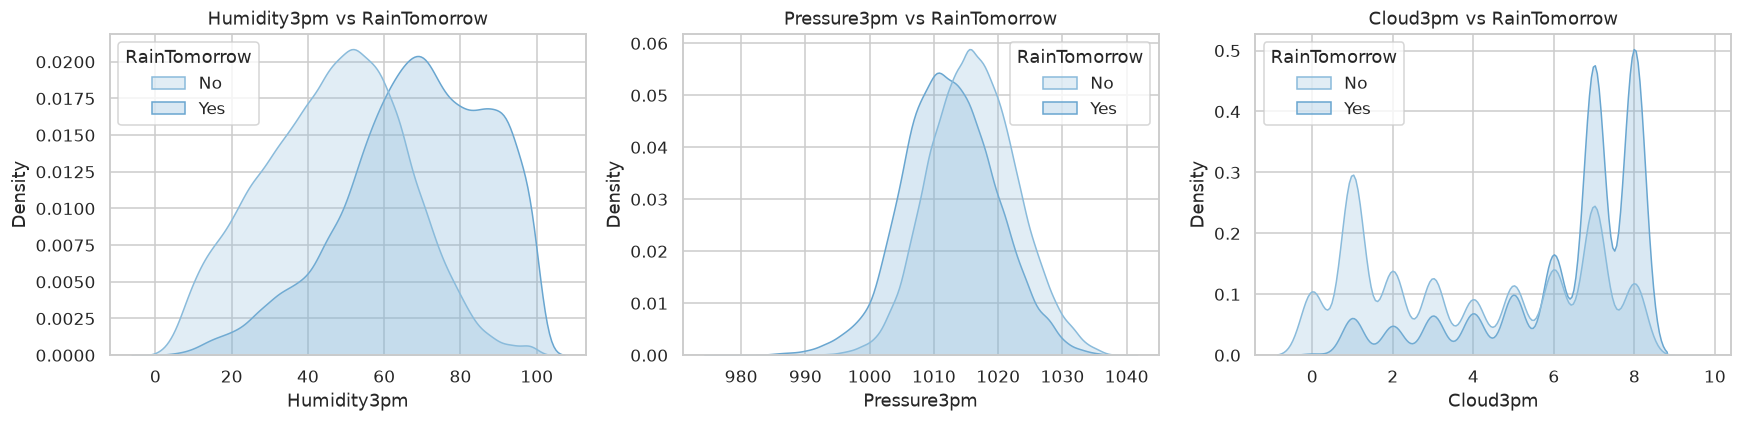

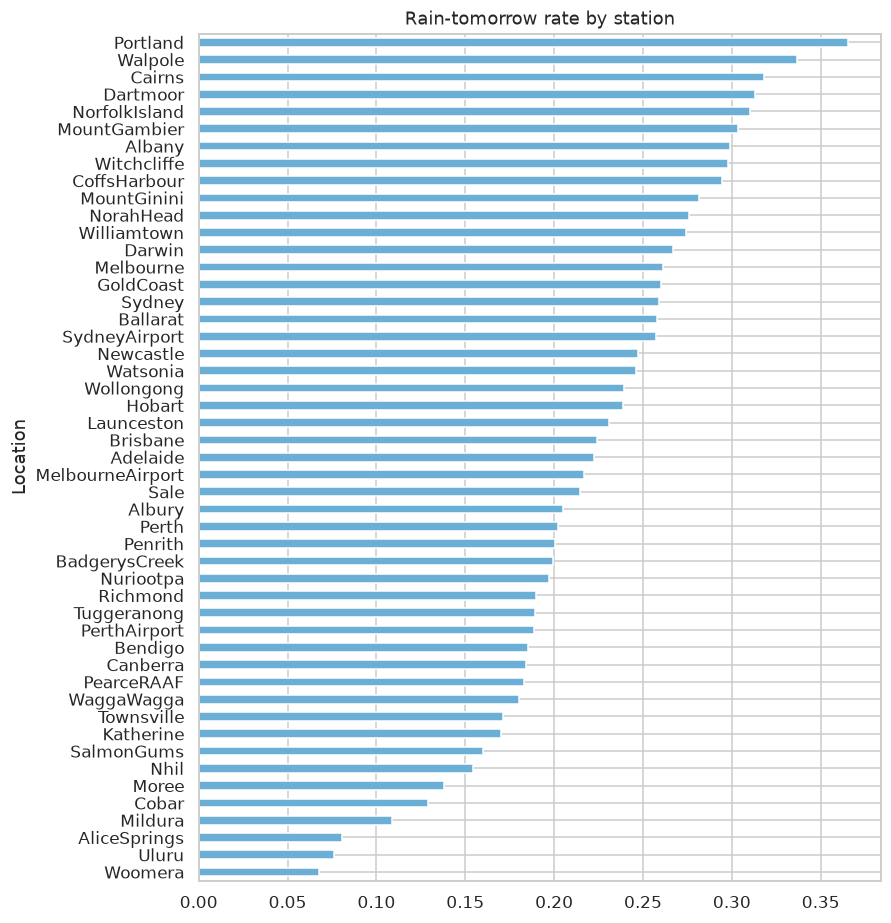

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ['Humidity3pm', 'Pressure3pm', 'Cloud3pm']):
    sns.kdeplot(data=raw.dropna(subset=['RainTomorrow']), x=col, hue='RainTomorrow', fill=True, common_norm=False, ax=a)
    a.set_title(f'{col} vs RainTomorrow')
plt.tight_layout(); plt.show()
top = raw.groupby('Location')['RainTomorrow'].apply(lambda s: (s == 'Yes').mean()).sort_values()
top.plot.barh(figsize=(8, 10), color='#6baed6', title='Rain-tomorrow rate by station'); plt.show()

## 4. Feature engineering and chronological split
* `RainToday` is encoded 0/1, cloud is capped at 8 oktas, and wind direction becomes **sin/cos** of the angle.
* New features: `HumidityDelta`, `PressureDelta` (pressure tendency) and `TempRange`.
* `Evaporation`/`Sunshine` are dropped (about 45% missing and not available from live APIs or cheap sensors).
* The split is **by time**: train up to 2014, validate on 2015, test on 2016–17. This tests the model on future data it has not seen.

In [7]:
df = load_dataset(DATA)
train, val, test = split_by_time(df)
medians = train[FEATURES].median().round(4).to_dict()
Xtr, Xva, Xte = impute(train, medians), impute(val, medians), impute(test, medians)
ytr, yva, yte = train.RainTomorrow.values, val.RainTomorrow.values, test.RainTomorrow.values
print(f'train {Xtr.shape}  val {Xva.shape}  test {Xte.shape}  features: {FEATURES}')

train (98988, 20)  val (17231, 20)  test (25974, 20)  features: ['MinTemp', 'MaxTemp', 'Rainfall', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'HumidityDelta', 'PressureDelta', 'TempRange', 'GustDirSin', 'GustDirCos']


## 5. Machine learning models

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_curve, confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error

scaler = StandardScaler().fit(Xtr)
models = {}
t = time.time()
models['Logistic Regression'] = LogisticRegression(max_iter=2000, C=0.5).fit(scaler.transform(Xtr), ytr)
models['Random Forest'] = RandomForestClassifier(n_estimators=200, max_depth=14, n_jobs=-1, random_state=42).fit(Xtr, ytr)
models['Gradient Boosting'] = GradientBoostingClassifier(n_estimators=250, max_depth=4, learning_rate=0.08, subsample=0.8, random_state=42).fit(Xtr, ytr)
models['Neural Network (MLP)'] = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=60, early_stopping=True, random_state=42).fit(scaler.transform(Xtr), ytr)
print(f'trained in {time.time()-t:.0f}s')

scaled = {'Logistic Regression', 'Neural Network (MLP)'}
proba = lambda name, X: models[name].predict_proba(scaler.transform(X) if name in scaled else X)[:, 1]
results = {name: metrics(yte, proba(name, Xte)) for name in models}
pd.DataFrame(results).T

trained in 86s


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.8375,0.7105,0.4896,0.5797,0.8497
Random Forest,0.8423,0.7439,0.4743,0.5792,0.8640
Gradient Boosting,0.8434,0.7227,0.5128,0.5999,0.8649
Neural Network (MLP),0.8448,0.7088,0.5466,0.6172,0.8679


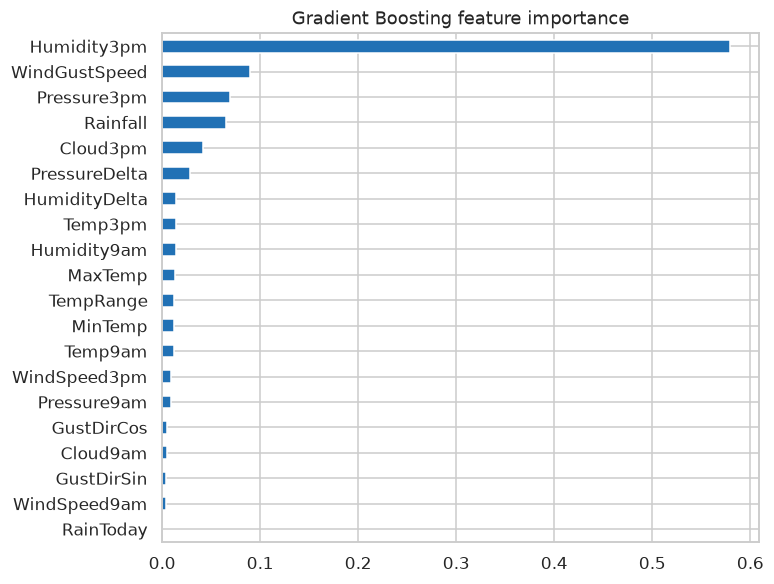

In [9]:
gbm = models['Gradient Boosting']
imp = pd.Series(gbm.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(7, 6), color='#2171b5', title='Gradient Boosting feature importance'); plt.show()

## 6. Soft computing
### 6a. Fuzzy inference system (Mamdani)
Four fuzzy inputs (humidity, pressure, pressure tendency, cloud) plus rain-today feed **18 expert rules** such as *IF humidity is humid AND cloud is overcast THEN rain is very_high*. The system uses min-AND, max aggregation and centroid defuzzification. The full implementation is in `rainlib/fuzzy.py` and needs no external library.

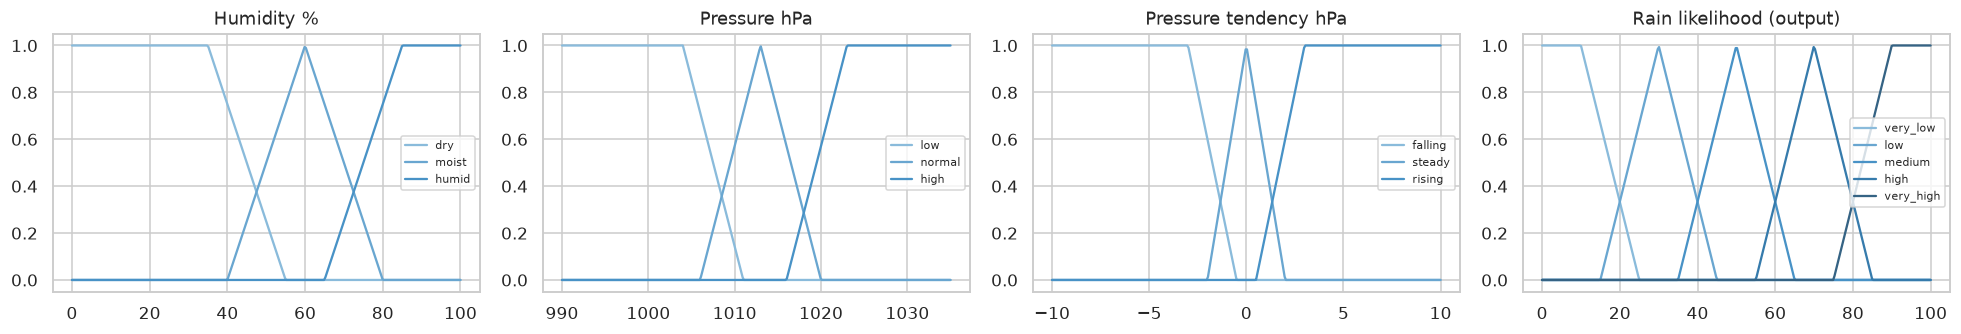

Example: likelihood = 81.5%


[{'if': {'hum': 'humid', 'cloud': 'overcast'},
  'then': 'very_high',
  'strength': 1.0},
 {'if': {'hum': 'humid', 'pres': 'low'}, 'then': 'very_high', 'strength': 1.0},
 {'if': {'hum': 'humid', 'tend': 'falling'}, 'then': 'high', 'strength': 1.0},
 {'if': {'rain_today': 'yes', 'hum': 'humid'},
  'then': 'very_high',
  'strength': 1.0}]

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.2))
for a, (name, mfs, rng) in zip(ax, [('Humidity %', fuzzy.HUMIDITY, np.linspace(0, 100, 300)),
                                    ('Pressure hPa', fuzzy.PRESSURE, np.linspace(990, 1035, 300)),
                                    ('Pressure tendency hPa', fuzzy.TENDENCY, np.linspace(-10, 10, 300)),
                                    ('Rain likelihood (output)', fuzzy.LIKELIHOOD, np.linspace(0, 100, 300))]):
    for term, f in mfs.items():
        a.plot(rng, [f(x) for x in rng], label=term)
    a.set_title(name); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

val_fz, det = fuzzy.rain_likelihood(humidity=88, pressure=1004, tendency=-3, cloud=7, rain_today=1, return_details=True)
print(f'Example: likelihood = {val_fz:.1f}%'); det['fired_rules'][:4]

In [11]:
fz_te = fuzzy_scores(Xte)
results['Fuzzy Inference'] = metrics(yte, fz_te)
print(results['Fuzzy Inference'])

{'accuracy': 0.7769, 'precision': 0.5113, 'recall': 0.5757, 'f1': 0.5416, 'roc_auc': 0.7839}


### 6b. Genetic algorithm ensemble optimisation
Chromosome = `[w_LR, w_GBM, w_Fuzzy, threshold]`. The GA uses tournament selection, BLX-alpha crossover, Gaussian mutation and elitism. Fitness is the **F1-score** on the 2015 validation year. The fuzzy weight has a floor of 0.10 so the interpretable expert component always takes part. This also makes the blend more robust when IoT nodes send only a few readings.

gen   0  best F1=0.6249  w=[0.066 0.62  0.313]  thr=0.348
gen  10  best F1=0.6323  w=[0.031 0.869 0.1  ]  thr=0.308
gen  20  best F1=0.6331  w=[0.  0.9 0.1]  thr=0.310
gen  30  best F1=0.6337  w=[0.001 0.899 0.1  ]  thr=0.308
gen  40  best F1=0.6337  w=[0.001 0.899 0.1  ]  thr=0.308


gen  50  best F1=0.6337  w=[0.001 0.899 0.1  ]  thr=0.308


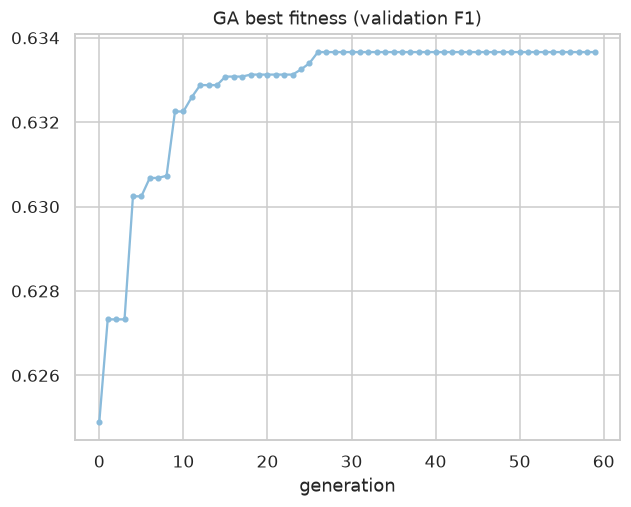

{'weights': {'logistic_regression': 0.0013, 'gbm': 0.8987, 'fuzzy': 0.1},
 'threshold': 0.308,
 'val_f1': 0.6337}

In [12]:
P_val = np.column_stack([proba('Logistic Regression', Xva), proba('Gradient Boosting', Xva), fuzzy_scores(Xva)])
ens, hist = optimise(P_val, yva, generations=60)
plt.plot(hist, marker='.'); plt.title('GA best fitness (validation F1)'); plt.xlabel('generation'); plt.show()
ens

,accuracy,precision,recall,f1,roc_auc
Fuzzy Inference,0.7769,0.5113,0.5757,0.5416,0.7839
Random Forest,0.8423,0.7439,0.4743,0.5792,0.8640
Logistic Regression,0.8375,0.7105,0.4896,0.5797,0.8497
Gradient Boosting,0.8434,0.7227,0.5128,0.5999,0.8649
Neural Network (MLP),0.8448,0.7088,0.5466,0.6172,0.8679
Hybrid GA Ensemble,0.8209,0.5936,0.6909,0.6385,0.8623


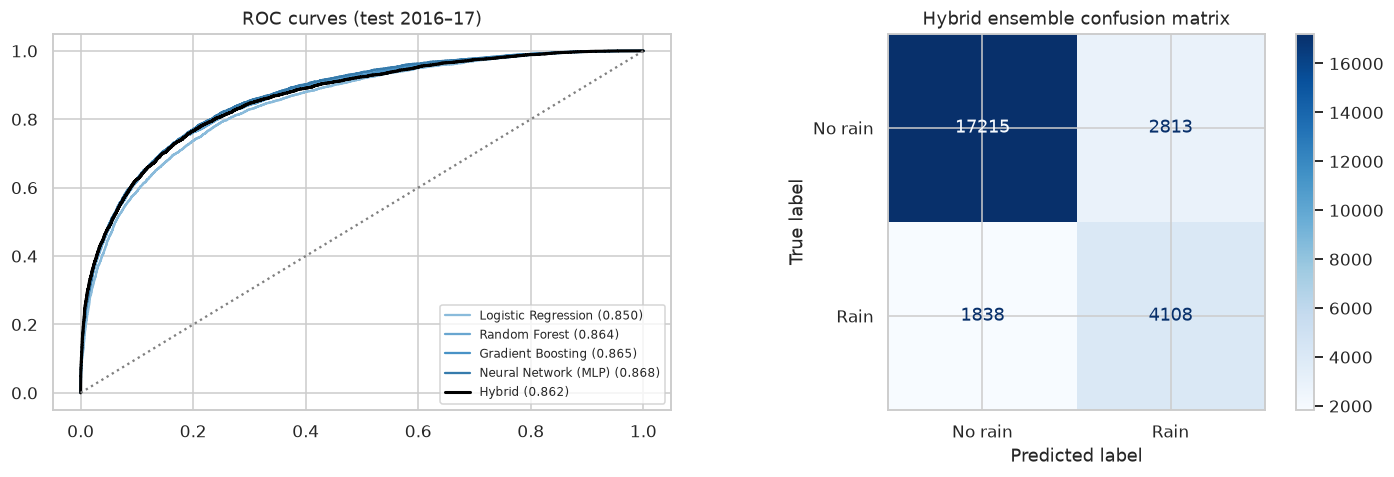

In [13]:
w = np.array([ens['weights']['logistic_regression'], ens['weights']['gbm'], ens['weights']['fuzzy']])
P_te = np.column_stack([proba('Logistic Regression', Xte), proba('Gradient Boosting', Xte), fz_te])
p_ens = P_te @ w
results['Hybrid GA Ensemble'] = metrics(yte, p_ens, ens['threshold'])
res_df = pd.DataFrame(results).T.sort_values('f1')
display(res_df)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name in models:
    fpr, tpr, _ = roc_curve(yte, proba(name, Xte)); ax[0].plot(fpr, tpr, label=f"{name} ({results[name]['roc_auc']:.3f})")
fpr, tpr, _ = roc_curve(yte, p_ens); ax[0].plot(fpr, tpr, 'k', lw=2, label=f"Hybrid ({results['Hybrid GA Ensemble']['roc_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], ':', c='grey'); ax[0].legend(fontsize=8); ax[0].set_title('ROC curves (test 2016–17)')
ConfusionMatrixDisplay(confusion_matrix(yte, (p_ens >= ens['threshold']).astype(int)), display_labels=['No rain', 'Rain']).plot(ax=ax[1], cmap='Blues')
ax[1].set_title('Hybrid ensemble confusion matrix'); plt.tight_layout(); plt.show()

## 7. Rain amount and rain type
A Gradient Boosting **regressor** predicts tomorrow's rainfall (log1p mm, from `RISK_MM`) on rainy days. Fuzzy memberships then map the amount to India Meteorological Department categories (drizzle, light, moderate, heavy, very heavy, extremely heavy). A fuzzy **convective index** (hot AND humid AND gusty/falling pressure) flags thunderstorms.

MAE on rainy test days: 6.97 mm


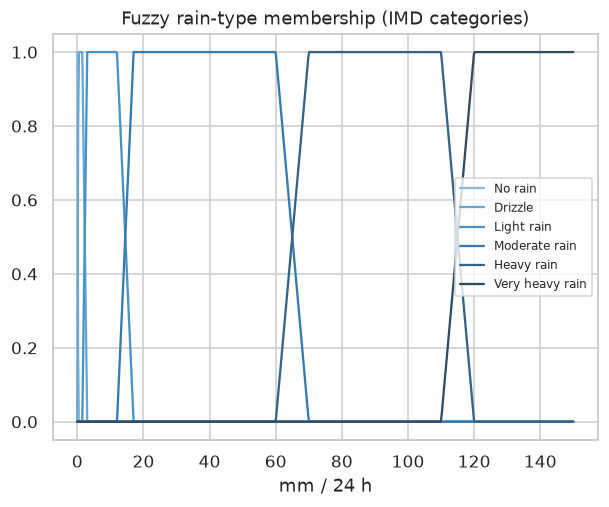

In [14]:
rainy = train[(train.RainTomorrow == 1) & train.RISK_MM.notna()]
reg = GradientBoostingRegressor(n_estimators=200, max_depth=4, learning_rate=0.08, subsample=0.8, random_state=42)
reg.fit(impute(rainy, medians), np.log1p(rainy.RISK_MM.values))
rainy_te = test[(test.RainTomorrow == 1) & test.RISK_MM.notna()]
mm = np.expm1(reg.predict(impute(rainy_te, medians)))
mae = mean_absolute_error(rainy_te.RISK_MM, mm)
print(f'MAE on rainy test days: {mae:.2f} mm')
mm_grid = np.linspace(0, 150, 600)
for k, f in fuzzy.INTENSITY.items():
    if k != 'Extremely heavy': plt.plot(mm_grid, [f(x) for x in mm_grid], label=k)
plt.legend(fontsize=8); plt.title('Fuzzy rain-type membership (IMD categories)'); plt.xlabel('mm / 24 h'); plt.show()

## 8. Export the models for the Vercel API

In [15]:
import datetime as dt
lr = models['Logistic Regression']
model_json = {
    'version': '1.0.0',
    'trained_on': f'Kaggle weatherAUS ({len(train)} train rows), exported {dt.date.today()}',
    'features': FEATURES, 'medians': medians,
    'logistic_regression': {'mean': scaler.mean_.round(6).tolist(), 'scale': scaler.scale_.round(6).tolist(),
                            'coef': lr.coef_[0].round(6).tolist(), 'intercept': round(float(lr.intercept_[0]), 6)},
    'gbm_classifier': {'init': gbm_init_raw(gbm, Xtr), 'learning_rate': gbm.learning_rate, 'trees': export_trees(gbm)},
    'gbm_regressor': {'init': gbm_init_raw(reg, Xtr), 'learning_rate': reg.learning_rate, 'trees': export_trees(reg)},
    'ensemble': {**ens, 'base_rate': round(float(ytr.mean()), 4)},
    'metrics': {'test_period': f'{test.Date.min().date()} to {test.Date.max().date()}', 'n_test': int(len(test)),
                'models': {k.lower().replace(' ', '_').replace('(', '').replace(')', ''): v for k, v in results.items()},
                'rain_amount_mae_mm': round(float(mae), 3)},
}
with open('rainlib/model.json', 'w') as fh:
    json.dump(model_json, fh, separators=(',', ':'))
print(f"rainlib/model.json  {os.path.getsize('rainlib/model.json')/1024:.0f} KB")

# parity check: pure-Python inference == scikit-learn
from rainlib import model as pm
pm.load_model.cache_clear(); m = pm.load_model()
print('max |diff| GBM:', max(abs(pm.gbm_proba(m, list(Xte[i])) - P_te[i, 1]) for i in range(300)))

rainlib/model.json  329 KB
max |diff| GBM: 2.710270881611798e-07


> The web app's model card expects these keys: `logistic_regression`, `random_forest`, `gradient_boosting`, `neural_network_mlp`, `fuzzy_inference`, `hybrid_ga_ensemble`. `python -m src.train` writes exactly these. To push a retrained model, commit `rainlib/model.json`; Vercel redeploys automatically.

## 9. Predict from current and historical weather (user input)

In [16]:
#@title Choose a city { run: "auto" }
CITY = "Mumbai"  #@param {type:"string"}
from rainlib.weather import geocode, current_features, climatology
from rainlib import predict
place = geocode(CITY)[0]
live = current_features(place['latitude'], place['longitude'])
clim = climatology(place['latitude'], place['longitude'])
res = predict(live['features'], climatology=clim['rain_frequency'])
print(f"{place['name']}, {place['country']}: {res['probability']*100:.0f}% chance of rain tomorrow -> {res['rain_type']['label']}")
print('Open-Meteo reference forecast:', live['reference_forecast'])
pd.DataFrame(live['history_7d']).set_index('date')

Mumbai, India: 10% chance of rain tomorrow -> No rain
Open-Meteo reference forecast: {'date': '2026-10-20', 'precip_probability_max': 51, 'precip_sum': 1.1}


,rain_mm,tmax,tmin
date,,,
2026-10-12,0.0,37.8,27.5
2026-10-13,0.0,38.1,27.4
2026-10-14,0.0,37.6,27.5
2026-10-15,0.0,37.5,27.7
2026-10-16,0.0,37.1,27.1
2026-10-17,0.7,36.0,27.5
2026-10-18,0.7,35.6,27.2


In [17]:
#@title Or enter your own readings
Humidity3pm = 85  #@param {type:"slider", min:0, max:100}
Pressure3pm = 1005  #@param {type:"slider", min:980, max:1040}
Pressure9am = 1008  #@param {type:"slider", min:980, max:1040}
Cloud3pm = 7  #@param {type:"slider", min:0, max:8}
MaxTemp = 31  #@param {type:"number"}
Rainfall = 5  #@param {type:"number"}
WindGustSpeed = 45  #@param {type:"number"}
r = predict(dict(Humidity3pm=Humidity3pm, Pressure3pm=Pressure3pm, Pressure9am=Pressure9am, Cloud3pm=Cloud3pm,
                 MaxTemp=MaxTemp, Rainfall=Rainfall, WindGustSpeed=WindGustSpeed))
{k: r[k] for k in ['probability', 'will_rain', 'condition', 'expected_mm_if_rain']} | {'rain_type': r['rain_type']['label']}

{'probability': 0.9121,
 'will_rain': True,
 'condition': 'Rain almost certain',
 'expected_mm_if_rain': 10.1,
 'rain_type': 'Thunderstorm'}

## 10. IoT: simulated sensor stream

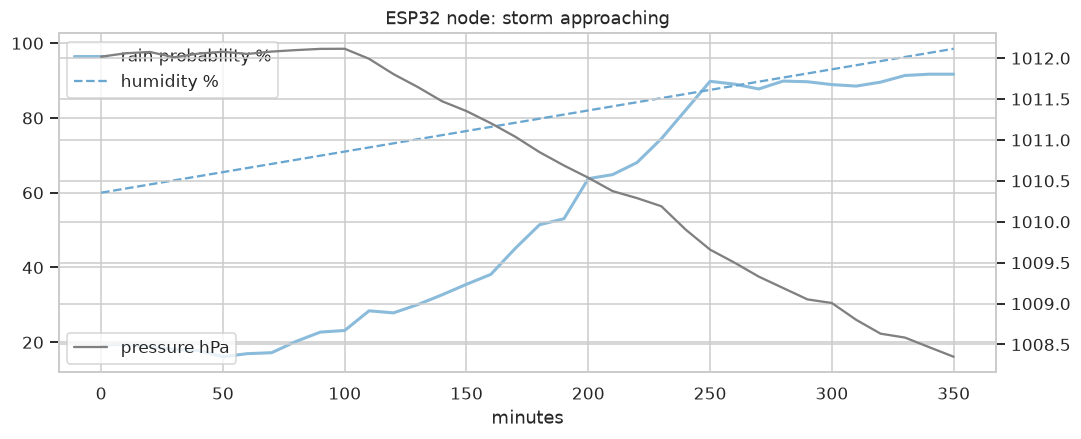

,t,temperature,humidity,pressure,pressure_3h_ago,rain_analog,gust_kmh,prob,type
31,310,28.52,94.1,1008.801136,1011.646243,900,51,0.8852,Thunderstorm
32,320,28.44,95.2,1008.632256,1011.472137,900,52,0.8957,Thunderstorm
33,330,28.36,96.3,1008.584394,1011.352079,900,53,0.9135,Thunderstorm
34,340,28.28,97.4,1008.466729,1011.204065,900,54,0.9170,Thunderstorm
35,350,28.20,98.5,1008.349883,1011.039442,900,55,0.9170,Thunderstorm


In [18]:
import sys; sys.path.insert(0, 'api')
from iot import sensor_to_inputs
rng = np.random.default_rng(1)
rows, p_hist = [], [1012.0]
for step in range(36):  # 6 hours at 10-minute intervals with a storm building
    p_now = p_hist[-1] - (0.15 if step > 10 else 0) + rng.normal(0, 0.05); p_hist.append(p_now)
    reading = {'temperature': 31 - step * 0.08, 'humidity': min(99, 60 + step * 1.1), 'pressure': p_now,
               'pressure_3h_ago': p_hist[max(0, len(p_hist) - 19)], 'rain_analog': 4000 if step < 25 else 900, 'gust_kmh': 20 + step}
    out = predict(sensor_to_inputs(reading))
    rows.append({'t': step * 10, **reading, 'prob': out['probability'], 'type': out['rain_type']['label']})
iot = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(11, 4)); ax.plot(iot.t, iot.prob * 100, lw=2, label='rain probability %')
ax.plot(iot.t, iot.humidity, '--', label='humidity %'); ax2 = ax.twinx(); ax2.plot(iot.t, iot.pressure, c='grey', label='pressure hPa')
ax.set_xlabel('minutes'); ax.legend(loc='upper left'); ax2.legend(loc='lower left'); plt.title('ESP32 node: storm approaching'); plt.show()
iot.tail()

## 11. Deploy
1. Commit the updated `rainlib/model.json` to GitHub.
2. On [vercel.com/new](https://vercel.com/new), import `OMDATTA/rain-prediction`. No build settings are needed; `vercel.json` handles them.
3. Point the ESP32 sketch at `https://<your-app>.vercel.app/api/iot`.